In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython import display as ipythondisplay

In [54]:
env = gym.make("CartPole-v1", render_mode="rgb_array")

high_state = env.observation_space.high
low_state = env.observation_space.low

In [55]:
high_state

array([4.8       ,        inf, 0.41887903,        inf], dtype=float32)

In [56]:
low_state

array([-4.8       ,        -inf, -0.41887903,        -inf], dtype=float32)

In [ ]:
# Learning Params
learning_rate = 0.1
discount = 0.95
runs = 50000
show_every = 2000
update_every = 100
epsilon = 1
start_epsilon_decaying = 1
end_epsilon_decaying = runs // 2
epsilon_decay_value = epsilon / (end_epsilon_decaying - start_epsilon_decaying)

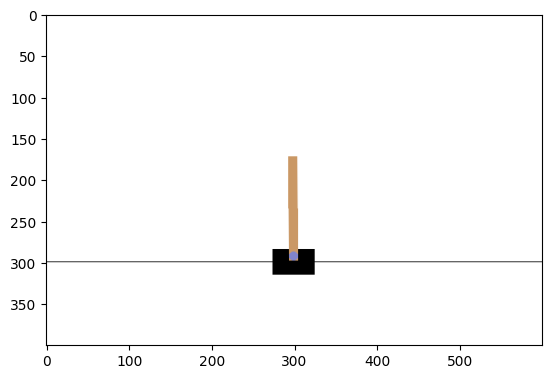

In [53]:
env.reset()
screen = env.render()
plt.imshow(screen)

In [57]:
def create_bins_and_qtable():
    NumBins = 20
    ObservationSpaceSize = len(high_state)

    bins = [
        np.linspace(-4.8, 4.8, NumBins),  # Cart Position
        np.linspace(-4, 4, NumBins), # Cart Velocity
        np.linspace(-0.418, 0.418, NumBins), # Pole Angle
        np.linspace(-4, 4, NumBins) # Pole Angular Velocity
    ]

    qTable = np.random.uniform(low=-2, high=0, size=([NumBins] * ObservationSpaceSize + [env.action_space.n]))
    print('QTable Size:', qTable.shape)

    return bins, ObservationSpaceSize, qTable

In [64]:
def get_discrete_state(state, bins, ObservationSpaceSize):
    StateIndex = []
    for i in range(ObservationSpaceSize):
        StateIndex.append(np.digitize(state[i], bins[i]) - 1)
    return tuple(StateIndex)

In [ ]:
bins, ObservationSpaceSize, qTable = create_bins_and_qtable()

previouseCnt = []
metrics ={'ep': [], 'avg': [], 'min': [], 'max': []}

QTable Size: (20, 20, 20, 20, 2)


In [ ]:
for run in range(runs):
    state, info = env.reset()
    discreteState = get_discrete_state(state=state, bins=bins, ObservationSpaceSize=ObservationSpaceSize)
    done = False
    Cnt = 0

    while not done:
        if run % show_every == 0:
            env.render()
        
        Cnt += 1
        if np.random.random() > epsilon:
            action = np.argmax(qTable[discreteState])
        else:
            action = np.random.randint(0, env.action_space.n)

        new_state, reward, done, *info = env.step(action)
        NewDiscreteState = get_discrete_state(new_state, bins, ObservationSpaceSize)

        MaxFeatureQ = np.max(qTable[NewDiscreteState])
        CurrentQ = qTable[discreteState + (action, )]

        if done and Cnt < 200:
            reward = -375

        NewQ = (1 - learning_rate) * CurrentQ + learning_rate * (reward + discount * MaxFeatureQ)
        qTable[discreteState + (action, )] = NewQ
        discreteState = NewDiscreteState

    previouseCnt.append(Cnt)

    if end_epsilon_decaying >= run >= start_epsilon_decaying:
        epsilon -= epsilon_decay_value

    if run % update_every == 0:
        LatestRun = previouseCnt[-update_every:]
        AvarageCnt = sum(LatestRun) / len(LatestRun)
        metrics['ep'].append(run)
        metrics['avg'].append(AvarageCnt)
        metrics['min'].append(min(LatestRun))
        metrics['max'].append(max(LatestRun))
        print(f'Run: {run}, Avarage: {AvarageCnt}, Min: {min(LatestRun)}, Max: {max(LatestRun)}')

NameError: name 'metrics' is not defined

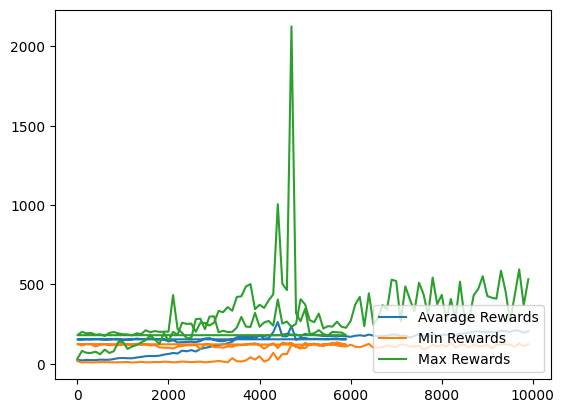

In [ ]:
env.close()
plt.plot(metrics['ep'], metrics['avg'], label='Avarage Rewards')
plt.plot(metrics['ep'], metrics['min'], label='Min Rewards')
plt.plot(metrics['ep'], metrics['max'], label='Max Rewards')
plt.legend(loc=4)
plt.show()

KeyboardInterrupt: 

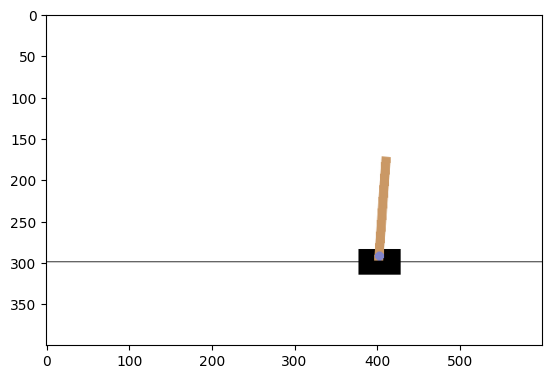

In [78]:
state, info = env.reset()
discrete_state = get_discrete_state(state, bins, ObservationSpaceSize)
done = False
total_reward = 0
step_count = 0

while not done:
    screen = env.render()
    plt.imshow(screen)
    ipythondisplay.clear_output(wait=True)
    ipythondisplay.display(plt.gcf())

    action = np.argmax(qTable[discrete_state])
    new_state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    step_count += 1
    discrete_state = get_discrete_state(new_state, bins, ObservationSpaceSize)

    if terminated or truncated:
        done = True

env.close()
print(f"Total reward: {total_reward}, Steps: {step_count}")